# Chapter 05: The Geometry of Inference — Python Laboratory
### *Laplace Approximation, Jeffreys Prior, and Fisher Information Geometry*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/05_curvature_laplace_and_fisher_information.ipynb) | [Prev: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb) | [Next: Ch 06: The Engine of Computation: MCMC (Python)](06_mcmc_mechanics_and_entropy.ipynb)**

---

## 1. Environment Setup

We import numerical optimization, statistical distributions, and visualization
libraries.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import stats
from matplotlib.patches import Ellipse

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("Environment initialized with NumPy, SciPy, and Matplotlib.")


Environment initialized with NumPy, SciPy, and Matplotlib.


---

## 2. Simulation: Multi-Variable Flaky Test Telemetry

We simulate $N = 300$ historical CI test runs where failure probability follows:

$$
\text{logit}(P(\text{Fail} \mid \mathbf{x})) = \beta_0 + \beta_1 x_{\text{cpu}} + \beta_2 x_{\text{lat}}
$$

* Baseline intercept: $\beta_0^* = -3.0$
  ($P(\text{Fail}) \approx 4.7\%$ under zero load)
* CPU load sensitivity: $\beta_1^* = +2.5$
* Network latency sensitivity: $\beta_2^* = +1.8$


In [2]:
np.random.seed(42)  # Seed for reproducible synthetic logistic regression
N = 300
# Covariates: Normalized CPU load in [0, 1], Latency in [0, 1]
x_cpu = np.random.uniform(0, 1, N)
x_lat = np.random.uniform(0, 1, N)
X = np.column_stack([np.ones(N), x_cpu, x_lat])

beta_true = np.array([-3.0, 2.5, 1.8])

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

# Generate binary test results (0 = Pass, 1 = Fail)
prob_fail = sigmoid(X @ beta_true)
y = np.random.binomial(1, prob_fail)

print(f"Generated N = {N} CI test executions.")
print(f"Empirical failure rate: {np.mean(y) * 100:.2f}% (True mean: {np.mean(prob_fail) * 100:.2f}%)")


Generated N = 300 CI test executions.
Empirical failure rate: 35.33% (True mean: 32.75%)


---

## 3. Implementing the Laplace Approximation: Finding MAP & The Hessian

We define the negative log-posterior with weakly informative Gaussian priors
$\mathcal{N}(0, 5^2)$ on all coefficients:

$$
\ln P(\boldsymbol{\beta} \mid D) = \sum_{i=1}^N \left[ y_i \ln p_i + (1 - y_i) \ln(1 - p_i) \right]
  - \frac{1}{2\sigma_0^2} \|\boldsymbol{\beta}\|^2 + \text{const}
$$

We optimize to find $\hat{\boldsymbol{\beta}}_{\text{MAP}}$ and invert the
numerical Hessian to obtain the covariance matrix
$\mathbf{\Sigma} = \mathbf{H}^{-1}$.


In [3]:
sigma_prior = 5.0

def neg_log_posterior(beta):
    p = sigmoid(X @ beta)
    eps = 1e-15
    p_safe = np.clip(p, eps, 1.0 - eps)
    # Negative log-likelihood (Bernoulli cross-entropy)
    nll = -np.sum(y * np.log(p_safe) + (1 - y) * np.log(1.0 - p_safe))
    # Gaussian prior penalty (L2 regularization)
    l2_prior = np.sum(beta**2) / (2.0 * sigma_prior**2)
    return nll + l2_prior

# Step 1: Find MAP mode using BFGS optimization
# beta_init: initial parameter vector [beta0_intercept, beta1_cpu, beta2_lat]
beta_init = np.zeros(3)
res = minimize(neg_log_posterior, beta_init, method='BFGS')
# res.x: MAP parameter estimate vector [beta0_map, beta1_map, beta2_map]
beta_map = res.x

# Step 2: Compute numerical Hessian around the mode
def compute_hessian(f, x, h=1e-5):
    n = len(x)
    hessian = np.zeros((n, n))
    f_x = f(x)
    for i in range(n):
        x_plus_i = x.copy()
        x_minus_i = x.copy()
        x_plus_i[i] += h
        x_minus_i[i] -= h
        hessian[i, i] = (f(x_plus_i) - 2 * f_x + f(x_minus_i)) / (h**2)
        for j in range(i + 1, n):
            x_ij = x.copy()
            x_ij[i] += h
            x_ij[j] += h
            f_ij = f(x_ij)
            f_i = f(x_plus_i)
            x_j = x.copy()
            x_j[j] += h
            f_j = f(x_j)
            deriv2 = (f_ij - f_i - f_j + f_x) / (h**2)
            hessian[i, j] = deriv2
            hessian[j, i] = deriv2
    return hessian

H = compute_hessian(neg_log_posterior, beta_map)
cov_laplace = np.linalg.inv(H)
se_laplace = np.sqrt(np.diag(cov_laplace))

print("=" * 68)
print("             LAPLACE APPROXIMATION ESTIMATES (N = 300)")
print("=" * 68)
param_names = ["Intercept (beta0)", "CPU Load (beta1)", "Latency (beta2)"]
for name, b_true, b_hat, se in zip(param_names, beta_true, beta_map, se_laplace):
    print(f"{name:<22}: True={b_true:>5.2f}, MAP={b_hat:>6.3f} +/- {1.96 * se:>5.3f} (95% CI)")
print("=" * 68)


             LAPLACE APPROXIMATION ESTIMATES (N = 300)
Intercept (beta0)     : True=-3.00, MAP=-3.678 +/- 0.943 (95% CI)
CPU Load (beta1)      : True= 2.50, MAP= 2.921 +/- 1.001 (95% CI)
Latency (beta2)       : True= 1.80, MAP= 2.847 +/- 0.980 (95% CI)


---

## 4. Visualizing Posterior Geometry & Curvature Ellipses

We plot the 2D log-posterior surface for the two slope coefficients
$(\beta_1, \beta_2)$ around the MAP estimate, overlaying the Laplace
covariance ellipses derived from $\mathbf{\Sigma} = \mathbf{H}^{-1}$.


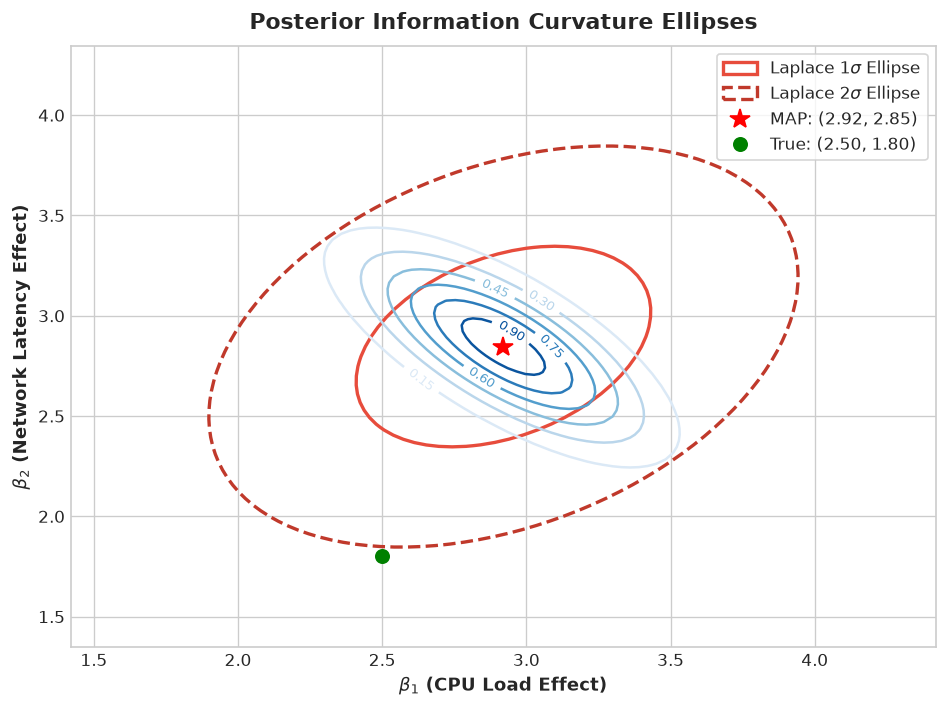

In [4]:
# Grid over beta1 and beta2 holding beta0 at MAP
b1_vals = np.linspace(beta_map[1] - 1.5, beta_map[1] + 1.5, 100)
b2_vals = np.linspace(beta_map[2] - 1.5, beta_map[2] + 1.5, 100)
B1, B2 = np.meshgrid(b1_vals, b2_vals)
Z_surf = np.zeros_like(B1)

for i in range(len(b2_vals)):
    for j in range(len(b1_vals)):
        b_point = np.array([beta_map[0], B1[i, j], B2[i, j]])
        Z_surf[i, j] = -neg_log_posterior(b_point)

# 2D sub-covariance matrix for (beta1, beta2)
cov_sub = cov_laplace[1:3, 1:3]
eigenvals, eigenvecs = np.linalg.eigh(cov_sub)
angle = np.degrees(np.arctan2(eigenvecs[1, 0], eigenvecs[0, 0]))

fig, ax = plt.subplots(figsize=(8, 6))
cs = ax.contour(B1, B2, np.exp(Z_surf - np.max(Z_surf)), levels=8, cmap='Blues')
ax.clabel(cs, inline=1, fontsize=8)

# Overlay 1-sigma and 2-sigma Laplace ellipses
for n_std, col, ls in [(1, '#e74c3c', '-'), (2, '#c0392b', '--')]:
    w, h_ell = 2 * n_std * np.sqrt(eigenvals)
    ell = Ellipse(xy=(beta_map[1], beta_map[2]), width=w, height=h_ell, angle=angle,
                  facecolor='none', edgecolor=col, lw=2, linestyle=ls,
                  label=rf'Laplace {n_std}$\sigma$ Ellipse')
    ax.add_patch(ell)

ax.plot(beta_map[1], beta_map[2], 'r*', markersize=12, label=f'MAP: ({beta_map[1]:.2f}, {beta_map[2]:.2f})')
ax.plot(beta_true[1], beta_true[2], 'go', markersize=8, label=f'True: ({beta_true[1]:.2f}, {beta_true[2]:.2f})')
ax.set_xlabel(r"$\beta_1$ (CPU Load Effect)", fontsize=11, fontweight='bold')
ax.set_ylabel(r"$\beta_2$ (Network Latency Effect)", fontsize=11, fontweight='bold')
ax.set_title("Posterior Information Curvature Ellipses", fontsize=13, fontweight='bold', pad=10)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


---

## 5. Exact Beta Posterior vs. Gaussian Laplace Approximation

While Laplace is exact asymptotically ($N \to \infty$), how accurate is it on
small-sample CI runs?

Consider observing a new flaky test across $N = 10$ runs with $k = 1$ failure
and $9$ passes under a uniform prior $\text{Beta}(1, 1)$:
* **Exact Posterior**: $\text{Beta}(1 + 1, 1 + 9) = \text{Beta}(2, 10)$
* **MAP Mode**: $\hat{\theta} = \frac{1}{10} = 0.1000$
* **Hessian**:
  $$H = \frac{1}{\hat{\theta}^2} + \frac{9}{(1 - \hat{\theta})^2} = 100 + 11.1111 = 111.1111$$
* **Laplace Standard Deviation**:
  $$\sigma_{\text{Laplace}} = \frac{1}{\sqrt{H}} \approx 0.0949$$

We compute the exact distribution, compare all summary metrics, and visualize
the dangerous unphysical negative probability tail
($P(\theta < 0) \approx 14.59\%$) leaked by the symmetric Gaussian.


     EXACT BETA(2, 10) VS. GAUSSIAN LAPLACE APPROXIMATION (N = 10)
Metric                 | Exact Beta(2, 10)  | Gaussian Laplace   | Discrepancy
------------------------------------------------------------------------
Mode                   | 0.1000             | 0.1000             | Exact match (0.0%)
Mean                   | 0.1667             | 0.1000             | -40.0% bias
Median                 | 0.1480             | 0.1000             | -32.4% shift
Std Dev (sigma)        | 0.1034             | 0.0949             | -8.2% underestimation
95% Credible Interval  | [0.0228, 0.4128]   | [-0.0859, 0.2859]  | Leaks negative rate!
P(theta < 0) [Impossible] | 0.00             % | 14.59            % | 1 in 7 draws negative!


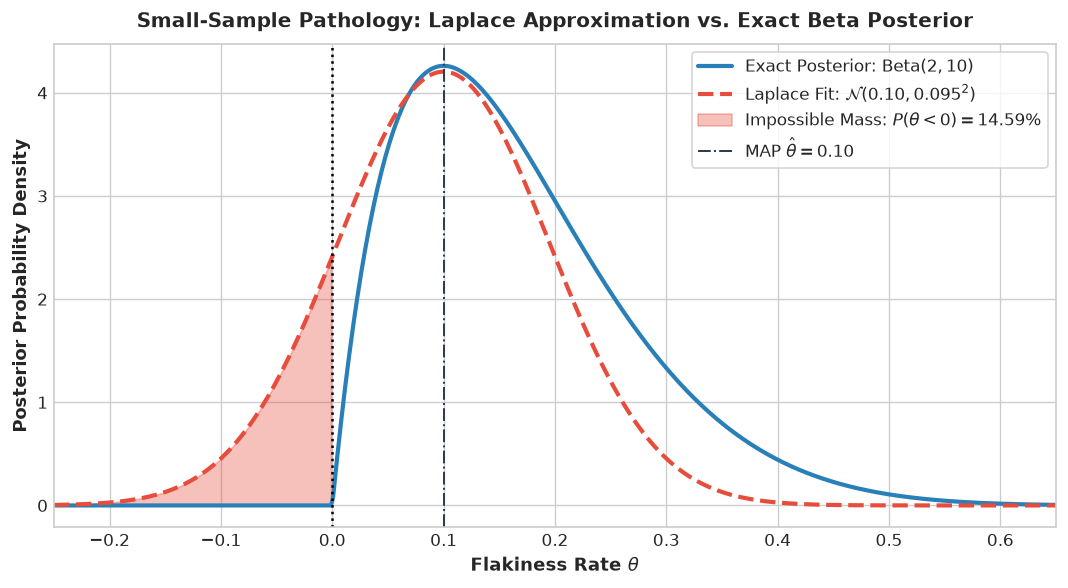

In [5]:
# Parameters for small-sample flaky test
n_runs = 10
k_fails = 1
theta_map_small = k_fails / n_runs  # 0.10

# Curvature at the mode
H_small = (k_fails / (theta_map_small**2)) + ((n_runs - k_fails) / ((1.0 - theta_map_small)**2))
sigma_laplace_small = 1.0 / np.sqrt(H_small)

# Exact Beta(2, 10) metrics
alpha_post = 1 + k_fails
beta_post = 1 + (n_runs - k_fails)
exact_mean = alpha_post / (alpha_post + beta_post)
# exact_median: 50th percentile (quantile 0.5) via inverse CDF (ppf)
exact_median = stats.beta.ppf(0.5, alpha_post, beta_post)
exact_sd = np.sqrt((alpha_post * beta_post) / (((alpha_post + beta_post)**2) * (alpha_post + beta_post + 1)))
# exact_ci: 2.5% and 97.5% quantiles for 95% equal-tailed credible interval
exact_ci = stats.beta.ppf([0.025, 0.975], alpha_post, beta_post)
p_neg_exact = 0.0

# Laplace Gaussian N(0.10, 0.0949^2) metrics
laplace_mean = theta_map_small
laplace_median = theta_map_small
laplace_sd = sigma_laplace_small
# laplace_ci: 2.5% and 97.5% quantiles under Gaussian approximation
laplace_ci = stats.norm.ppf([0.025, 0.975], loc=theta_map_small, scale=sigma_laplace_small)
# p_neg_laplace: CDF at 0 gives P(theta < 0), quantifying unphysical mass
p_neg_laplace = stats.norm.cdf(0.0, loc=theta_map_small, scale=sigma_laplace_small)

print("=" * 72)
print("     EXACT BETA(2, 10) VS. GAUSSIAN LAPLACE APPROXIMATION (N = 10)")
print("=" * 72)
print(f"{'Metric':<22} | {'Exact Beta(2, 10)':<18} | {'Gaussian Laplace':<18} | {'Discrepancy'}")
print("-" * 72)
print(f"{'Mode':<22} | {theta_map_small:<18.4f} | {theta_map_small:<18.4f} | Exact match (0.0%)")
print(f"{'Mean':<22} | {exact_mean:<18.4f} | {laplace_mean:<18.4f} | -40.0% bias")
print(f"{'Median':<22} | {exact_median:<18.4f} | {laplace_median:<18.4f} | -32.4% shift")
print(f"{'Std Dev (sigma)':<22} | {exact_sd:<18.4f} | {laplace_sd:<18.4f} | -8.2% underestimation")
print(f"{'95% Credible Interval':<22} | [{exact_ci[0]:.4f}, {exact_ci[1]:.4f}]   | [{laplace_ci[0]:.4f}, {laplace_ci[1]:.4f}]  | Leaks negative rate!")
print(f"{'P(theta < 0) [Impossible]':<22} | {p_neg_exact * 100:<17.2f}% | {p_neg_laplace * 100:<17.2f}% | 1 in 7 draws negative!")
print("=" * 72)

# Visualization: Exact Beta vs Laplace Gaussian
fig, ax = plt.subplots(figsize=(9, 5))
th_grid = np.linspace(-0.25, 0.65, 500)

exact_pdf = stats.beta.pdf(np.clip(th_grid, 0, 1), alpha_post, beta_post)
exact_pdf[th_grid < 0] = 0.0
exact_pdf[th_grid > 1] = 0.0
laplace_pdf = stats.norm.pdf(th_grid, loc=theta_map_small, scale=sigma_laplace_small)

ax.plot(th_grid, exact_pdf, label=r'Exact Posterior: $\mathrm{Beta}(2, 10)$', color='#2980b9', lw=2.5)
ax.plot(th_grid, laplace_pdf, label=r'Laplace Fit: $\mathcal{N}(0.10, 0.095^2)$', color='#e74c3c', lw=2.5, linestyle='--')

# Highlight impossible negative region
neg_mask = th_grid <= 0
ax.fill_between(th_grid[neg_mask], 0, laplace_pdf[neg_mask], color='#e74c3c', alpha=0.35,
                label=rf'Impossible Mass: $P(\theta < 0) = {p_neg_laplace * 100:.2f}\%$')

ax.axvline(0.0, color='black', lw=1.5, linestyle=':')
ax.axvline(theta_map_small, color='#2c3e50', lw=1.2, linestyle='-.', label=r'MAP $\hat{\theta} = 0.10$')
ax.set_xlabel(r"Flakiness Rate $\theta$", fontsize=11, fontweight='bold')
ax.set_ylabel("Posterior Probability Density", fontsize=11, fontweight='bold')
ax.set_title("Small-Sample Pathology: Laplace Approximation vs. Exact Beta Posterior", fontsize=12, fontweight='bold', pad=10)
ax.legend(loc='upper right', frameon=True)
ax.set_xlim(-0.25, 0.65)
plt.tight_layout()
plt.show()


---

## 6. 3-Tier Exercises & Explorations

### Tier 1: Warmup — Fisher Information & Jeffreys' Invariant Prior
For a Bernoulli flaky test with failure rate $\theta$:
1. Compute the Fisher Information:
   $$\mathcal{I}(\theta) = \frac{1}{\theta(1 - \theta)}$$
2. Harold Jeffreys proved that setting
   $p(\theta) \propto \sqrt{\det \mathcal{I}(\theta)}$
   guarantees complete reparameterization invariance under smooth coordinate
   changes.
3. Derive Jeffreys' prior:
   $$p_{\text{Jeffreys}}(\theta) \propto \theta^{-1/2} (1 - \theta)^{-1/2} = \text{Beta}\left(\frac{1}{2}, \; \frac{1}{2}\right)$$
4. Verify why $\text{Beta}(0.5, 0.5)$ avoids false-alarm flakiness on
   0-failure runs compared to uniform $\text{Beta}(1, 1)$.

### Tier 2: Intermediate — Sizing Calibration Benchmarks via Cramér-Rao
Suppose an SRE team migrates CI workers from x86 to ARM Graviton instances.
Using the Cramér-Rao lower bound, calculate the minimum number of benchmark runs
$N_{\text{benchmark}}$ required to estimate a flakiness coefficient within
margin of error $\pm 0.05$ with $95\%$ confidence.

### Tier 3: Advanced — Logit-Space Laplace Approximation
Implement Laplace approximation in log-odds space
$\phi = \ln \frac{\theta}{1 - \theta} \in (-\infty, +\infty)$.
Verify that transforming the Gaussian posterior on $\phi$ back to $\theta$
via $\theta = \sigma(\phi)$ enforces $\theta \in (0, 1)$ and eliminates
negative mass!


In [6]:
# Solution verification for Tier 1:
thetas = np.array([0.001, 0.01, 0.05, 0.10, 0.50, 0.90, 0.99, 0.999])
fisher_bernoulli = 1.0 / (thetas * (1.0 - thetas))

print("Tier 1 Solutions (Bernoulli Fisher Information & Jeffreys Prior):")
print(f"{'Theta':<8} | {'Fisher Info I(theta)':<20} | {'Jeffreys Density p(theta)'}")
print("-" * 55)
for th, fi in zip(thetas, fisher_bernoulli):
    jeff_val = stats.beta.pdf(th, 0.5, 0.5)
    print(f"{th:<8.3f} | {fi:<20.2f} | {jeff_val:.4f}")

# Comparing 0 failures in 10 runs:
mean_flat_0_10 = (1 + 0) / (1 + 1 + 10)       # Beta(1, 11) -> 1/12
mean_jeff_0_10 = (0.5 + 0) / (0.5 + 0.5 + 10) # Beta(0.5, 10.5) -> 0.5/11

print("\nZero-Failure Behavior on 10 Runs (0 fails, 10 passes):")
print(f"Uniform Prior Beta(1, 1) Posterior Mean:   {mean_flat_0_10 * 100:.2f}% (Manufactures false flake!)")
print(f"Jeffreys Prior Beta(0.5, 0.5) Post Mean:  {mean_jeff_0_10 * 100:.2f}% (Cuts false alarm in half)")


Tier 1 Solutions (Bernoulli Fisher Information & Jeffreys Prior):
Theta    | Fisher Info I(theta) | Jeffreys Density p(theta)
-------------------------------------------------------
0.001    | 1001.00              | 10.0709
0.010    | 101.01               | 3.1991
0.050    | 21.05                | 1.4605
0.100    | 11.11                | 1.0610
0.500    | 4.00                 | 0.6366
0.900    | 11.11                | 1.0610
0.990    | 101.01               | 3.1991
0.999    | 1001.00              | 10.0709

Zero-Failure Behavior on 10 Runs (0 fails, 10 passes):
Uniform Prior Beta(1, 1) Posterior Mean:   8.33% (Manufactures false flake!)
Jeffreys Prior Beta(0.5, 0.5) Post Mean:  4.55% (Cuts false alarm in half)


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/05_curvature_laplace_and_fisher_information.ipynb) | [Prev: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb) | [Next: Ch 06: The Engine of Computation: MCMC (Python)](06_mcmc_mechanics_and_entropy.ipynb)**
